In [9]:
import pandas as pd
import numpy as np

In [10]:

from pandas import read_csv
df=read_csv('C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv'
)
print("Dataset shape:", df.shape)

Dataset shape: (900, 77)


In [11]:
numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = df.select_dtypes(
    include=['object']
).columns

print("Numerical Features:", list(numerical_features))
print("Categorical Features:", list(categorical_features))

Numerical Features: ['id', 'ccf', 'age', 'sex', 'painloc', 'painexer', 'relrest', 'pncaden', 'cp', 'trestbps', 'htn', 'chol', 'smoke', 'cigs', 'fbs', 'dm', 'famhist', 'restecg', 'ekgmo', 'ekgyr', 'dig', 'prop', 'nitr', 'pro', 'proto', 'thaldur', 'thaltime', 'met', 'thalach', 'thalrest', 'tpeakbps', 'tpeakbpd', 'dummy', 'trestbpd', 'exang', 'xhypo', 'oldpeak', 'slope', 'rldv5', 'rldv5e', 'ca', 'restckm', 'exerckm', 'restef', 'restwm', 'exeref', 'exerwm', 'thal', 'thalsev', 'thalpul', 'earlobe', 'cday', 'cyr', 'num', 'lmt', 'ladprox', 'laddist', 'diag', 'cxmain', 'ramus', 'om1', 'om2', 'rcaprox', 'rcadist', 'lvx1', 'lvx2', 'lvx3', 'lvx4', 'lvf', 'cathef', 'junk']
Categorical Features: ['source', 'years', 'ekgday', 'diuretic', 'cmo', 'name']


C:\Users\User\AppData\Local\Temp\ipykernel_8972\4253390584.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [12]:
# Select only numerical columns for correlation
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[numerical_cols].corr()

In [13]:
# Select numerical columns
numerical_cols = df.select_dtypes(
    include=[np.number]
).columns.tolist()

# Calculate correlation matrix
corr_matrix = df[numerical_cols].corr()

print("\n--- Correlation Matrix ---")
print(corr_matrix)


--- Correlation Matrix ---
               id       ccf       age       sex   painloc  painexer   relrest  \
id       1.000000 -0.026756 -0.090098  0.066530  0.449943  0.462378  0.454718   
ccf     -0.026756  1.000000 -0.215646  0.017138  0.023077 -0.049042  0.025094   
age     -0.090098 -0.215646  1.000000  0.058414 -0.069522 -0.039773 -0.063856   
sex      0.066530  0.017138  0.058414  1.000000  0.192632  0.201920  0.199290   
painloc  0.449943  0.023077 -0.069522  0.192632  1.000000  0.993266  0.986175   
...           ...       ...       ...       ...       ...       ...       ...   
lvx3    -0.193358 -0.200551  0.027954 -0.047008 -0.089811 -0.078725 -0.088210   
lvx4    -0.196054  0.067088  0.036778  0.060540 -0.003128 -0.003206 -0.001009   
lvf     -0.126938  0.182336 -0.055148 -0.029437 -0.063319 -0.079257 -0.061966   
cathef   0.693039 -0.016569  0.069829  0.112699  0.331986  0.346946  0.338883   
junk    -0.275891 -0.012928  0.225187  0.166311  0.265437  0.267571  0.253961   


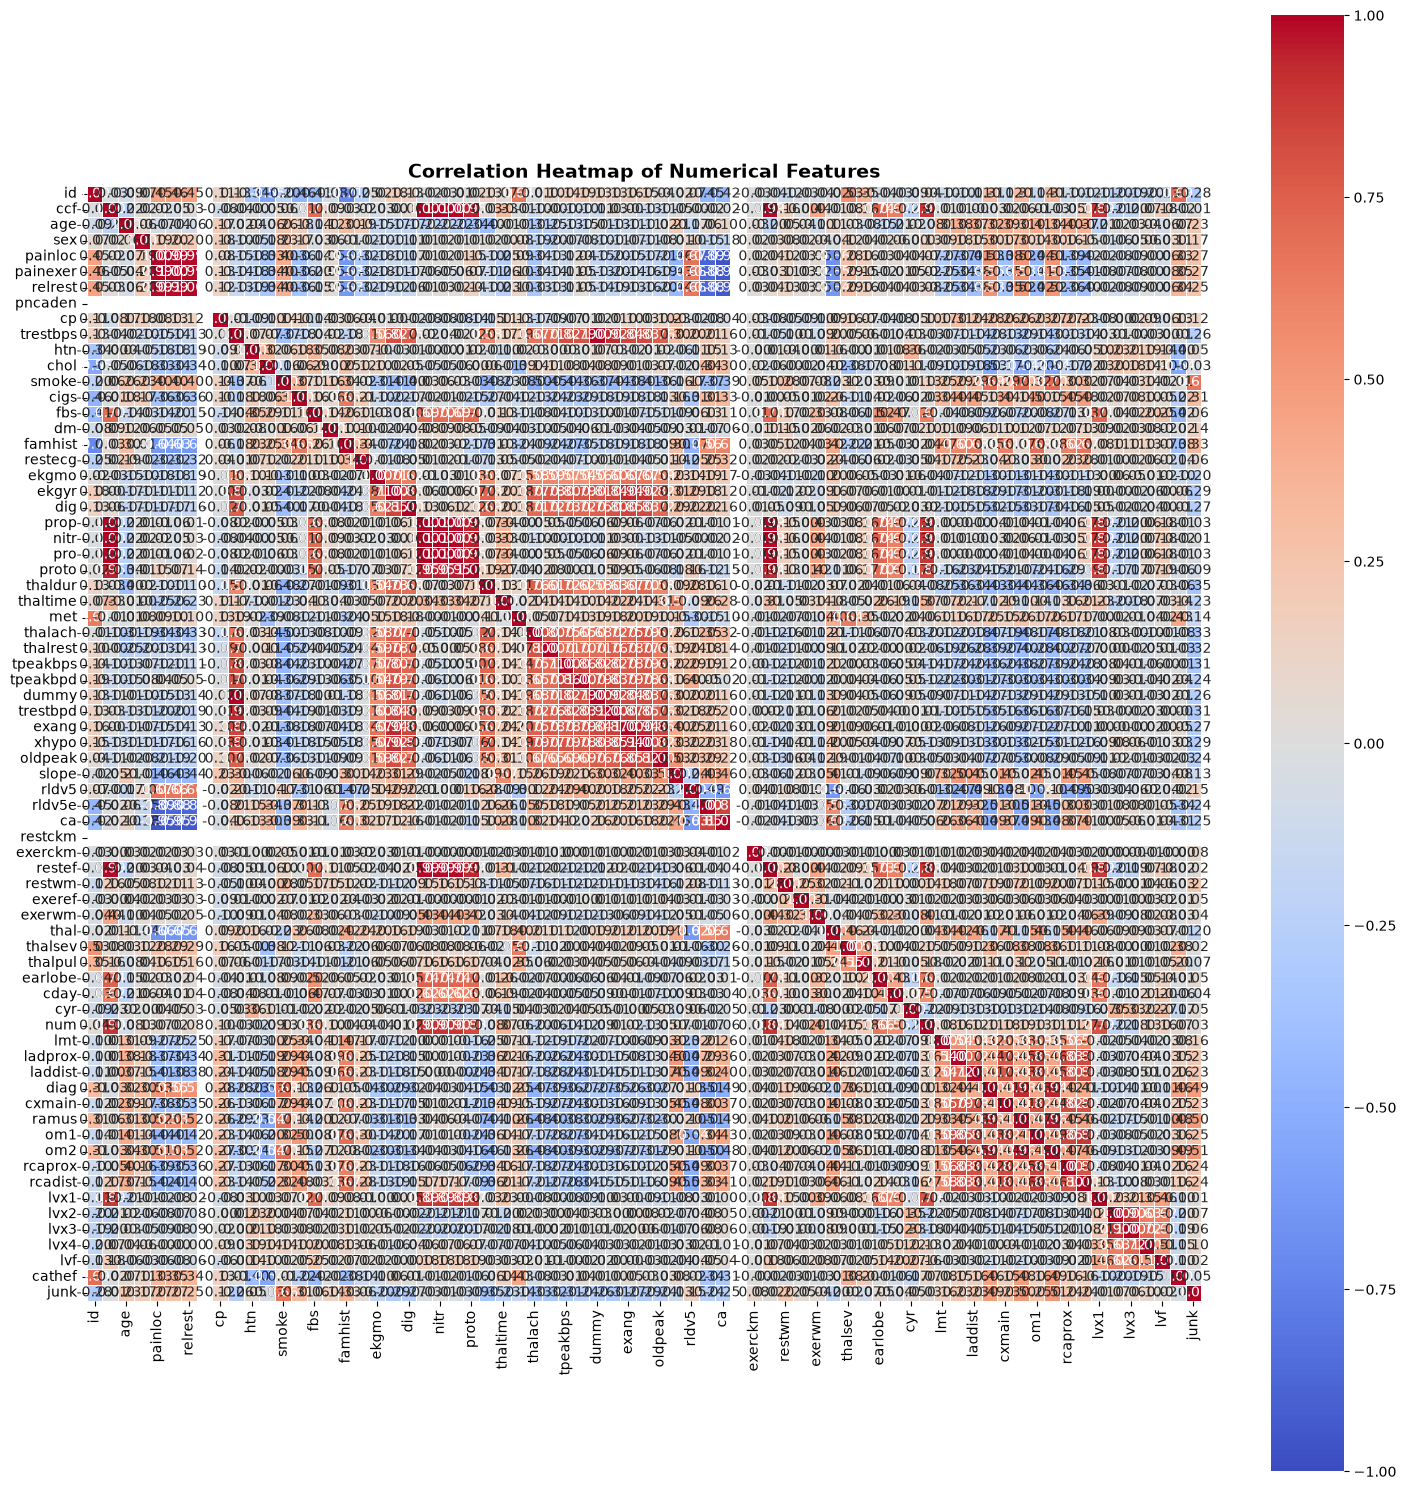

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(15, 15))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap of Numerical Features",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [15]:
# Create Heatmap
import matplotlib.pyplot as plt
plt.figure(figsize=(15,15))
sns.heatmap(
corr_matrix,
annot=True,
cmap="coolwarm",
fmt=".2f",
vmin=-1,
vmax=1,
square=True,
linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight="bold")
plt.tight_layout()

# Export Heatmap
import os
output_dir = "C:\\Users\\User\\Downloads\\heart+disease"
heatmap_path = os.path.join(output_dir, "correlation_heatmap.png")
plt.savefig(heatmap_path, dpi=300)
plt.close()
print(f"Exported heatmap to: {heatmap_path}")

Exported heatmap to: C:\Users\User\Downloads\heart+disease\correlation_heatmap.png


In [16]:

print(os.getcwd())

c:\Users\User\Downloads\heart+disease


In [17]:
# Create binary disease status
df["DiseaseStatus"] = (df["num"] > 0).astype(int)

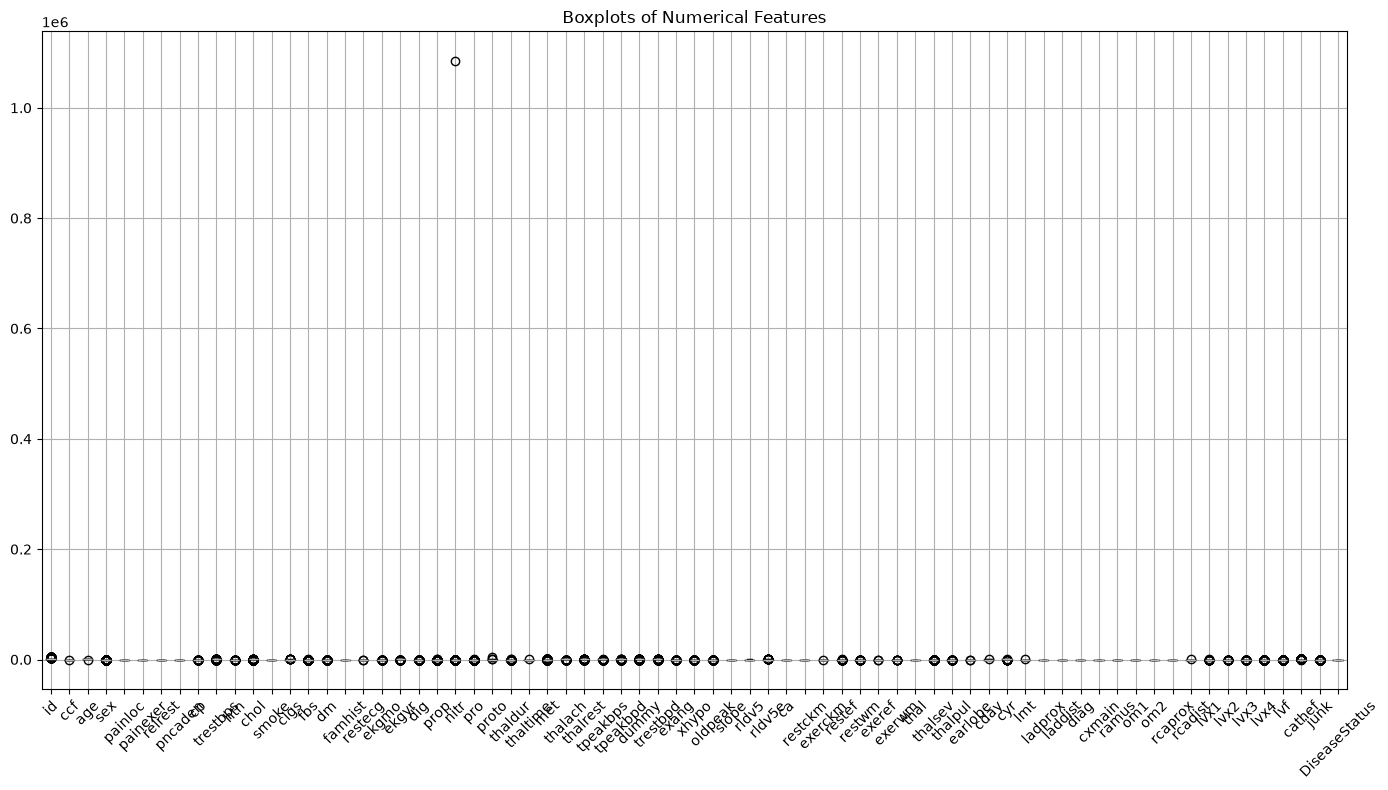

In [18]:
# ============================================================
# BOXPLOTS - HEART DISEASE DATASET
# ============================================================

# Create binary disease status
df["DiseaseStatus"] = (df["num"] > 0).astype(int)

# Get numerical columns automatically
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Remove the original target column
if "num" in numerical_columns:
    numerical_columns.remove("num")

# Create boxplots
fig6 = plt.figure(figsize=(14, 8))

df[numerical_columns].boxplot()

plt.xticks(rotation=45)
plt.title("Boxplots of Numerical Features")
plt.tight_layout()
plt.show()

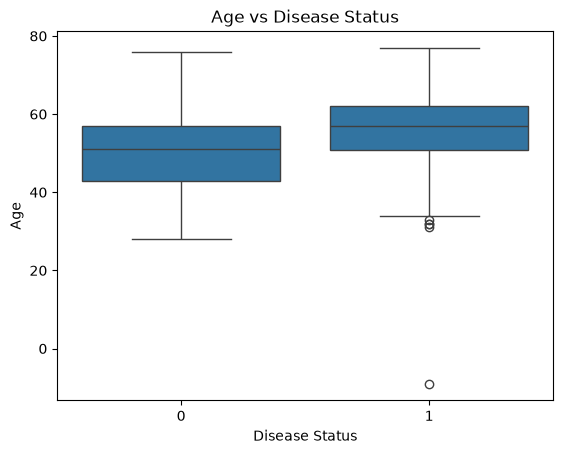

In [19]:
# Boxplot: Age vs Disease Status

fig7 = sns.boxplot(
    x="DiseaseStatus",
    y="age",
    data=df
)

plt.title("Age vs Disease Status")
plt.xlabel("Disease Status")
plt.ylabel("Age")

plt.show()

In [20]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

with PdfPages("EDA_Report.pdf") as pdf:
    for num in plt.get_fignums():
        fig = plt.figure(num)
        pdf.savefig(fig)

print("EDA Report saved successfully.")

EDA Report saved successfully.


In [21]:
# ==========================================================
# Export Complete EDA Report - HEART DISEASE DATASET
# ==========================================================

from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create binary disease status
df["DiseaseStatus"] = (df["num"] > 0).astype(int)

with PdfPages("EDA_Report.pdf") as pdf:

    # ------------------------------------------------------
    # Page 1 : Missing Value Heatmap
    # ------------------------------------------------------

    plt.figure(figsize=(12, 6))

    sns.heatmap(
        df.isnull(),
        cbar=True,
        yticklabels=False,
        cmap="viridis"
    )

    plt.title("Missing Value Heatmap")
    plt.xlabel("Features")
    plt.ylabel("Samples")

    pdf.savefig()
    plt.close()


    # ------------------------------------------------------
    # Page 2 : Histograms
    # ------------------------------------------------------

    numerical_features = [
        col for col in df.select_dtypes(include=np.number).columns
        if col not in ["num", "DiseaseStatus"]
    ]

    # Create enough rows for all numerical features
    n = len(numerical_features)
    cols = 3
    rows = int(np.ceil(n / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, 4 * rows)
    )

    axes = np.array(axes).flatten()

    for i, col in enumerate(numerical_features):

        axes[i].hist(
            df[col].dropna(),
            bins=15,
            edgecolor="black"
        )

        axes[i].set_title(col)
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")

    # Hide unused plots
    for i in range(len(numerical_features), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()

    pdf.savefig()
    plt.close()


    # ------------------------------------------------------
    # Page 3 : Disease Status
    # ------------------------------------------------------

    plt.figure(figsize=(8, 6))

    sns.countplot(
        data=df,
        x="DiseaseStatus"
    )

    plt.title("Disease Status Distribution")
    plt.xlabel("Disease Status")
    plt.ylabel("Number of Patients")

    plt.xticks(
        [0, 1],
        ["No Disease", "Disease"]
    )

    pdf.savefig()
    plt.close()


    # ------------------------------------------------------
    # Page 4 : Correlation Heatmap
    # ------------------------------------------------------

    plt.figure(figsize=(14, 12))

    corr = df.select_dtypes(
        include=np.number
    ).corr()

    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")

    plt.tight_layout()

    pdf.savefig()
    plt.close()


    # ------------------------------------------------------
    # Page 5 : Boxplots
    # ------------------------------------------------------

    n = len(numerical_features)
    cols = 3
    rows = int(np.ceil(n / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, 4 * rows)
    )

    axes = np.array(axes).flatten()

    for i, col in enumerate(numerical_features):

        sns.boxplot(
            y=df[col],
            ax=axes[i]
        )

        axes[i].set_title(
            f"Boxplot of {col}"
        )

        axes[i].set_ylabel(col)

    # Hide unused plots
    for i in range(len(numerical_features), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()

    pdf.savefig()
    plt.close()


print("EDA_Report.pdf created successfully.")

EDA_Report.pdf created successfully.
